# New-watch bicep curls — train on everyone
Fit one eight-feature Isolation Forest using all extracted repetitions from all four participants. No old or Mbient recordings are used. The histogram shows training anomaly scores, not held-out performance.

All six new-watch bicep files are included using the selected first-wearing movement windows. Later sets and reattachment periods remain excluded pending annotation. Labels are assumed typical. The provisional threshold is the 95th percentile of training scores; it does not establish detection accuracy or a future false-positive rate.

Run All using the project ml/.venv kernel. Each run saves a new output folder; the live app model is unchanged.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
import csv,json,re,hashlib,sys,pickle,platform,warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import balanced_accuracy_score,roc_auc_score,confusion_matrix
import sklearn,scipy
REPO=Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
WATCH_DIR=Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005')
OUTPUT=Path.cwd()/'bicep_watch_only_runs'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ');OUTPUT.mkdir(parents=True,exist_ok=False)
SEED=42
# First wearing periods only: session ID suffix -> movement window, seconds.
WATCH_WINDOWS={'1d1d07ea':(7,29),'1977cad0':(5,37),'efda0dcf':(5,44),
               '1ce3d7f5':(7,52),'15c80026':(7,37),'53c6c2fd':(6,36)}
print('Outputs:',OUTPUT)


Outputs: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_watch_only_runs/20261017T170731771444Z


## 1 Load all new-watch bicep recordings
All four participants and both recorded arms contribute to training. There is no test split in this notebook.

In [2]:
def readcsv(p):
    with Path(p).open(newline='') as f:return list(csv.DictReader(f))
def digest(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
manifest=[]
split_map={p:'train' for p in ['anisha','ashritha','angel','arshaan']}
for p in sorted(WATCH_DIR.glob('*.csv')):
    h=json.loads(p.with_suffix('.json').read_text()).get('homestretch',{})
    if h.get('exercise_id')!='bicep_curl':continue
    person=h.get('patient_id','unknown').strip().lower()
    assert person in split_map, 'Assign any additional participant before running.'
    key=p.stem.rsplit('_',1)[-1]
    assert key in WATCH_WINDOWS,'Annotate movement window for additional recording.'
    manifest.append(dict(session_id=f'session_{len(manifest):03d}',source='watch',file=str(p),participant=person,side=h.get('side'),label=0,label_status='assumed typical, unverified',split=split_map[person],window=WATCH_WINDOWS[key],sha256=digest(p)))
assert len(manifest)==6
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
for r in manifest:print(r['participant'],r['side'],r['split'],r['window'])


anisha right train (7, 29)
angel right train (5, 37)
angel left train (5, 44)
arshaan right train (7, 52)
ashritha left train (7, 37)
ashritha right train (6, 36)


## 2 Shared preprocessing and complete repetitions
Convert inputs to acceleration including gravity in g and gyroscope in degrees/s. Align to a 50 Hz grid using previous samples only; exclude stale data and reset on gaps longer than 60 ms. Estimate gyro bias only when at least one second of the existing initial lead-in meets the stationary check. This initialization must finish before live rep feedback starts. No additional recording is required.

A gyro/gravity quaternion estimator supplies start-to-end completion error and rotation excursion for segmentation. It never converts to Euler angles. Gravity feedback is gated by acceleration magnitude. A trailing five-sample mean smooths the **segmentation excursion only**; feature magnitudes retain the frequency band used for the spectral ratio.

A full excursion rise and return defines a candidate curl. The next rise confirms its end, causing a recorded delay and potentially leaving the final rep unconfirmed. We do not segment on gyroscope magnitude peaks, which can occur twice per curl. Boundaries remain experimental and must be checked in the review plot. Completion error is not used to exclude abnormal repetitions.

No zero-centering or amplitude normalization of the magnitude signals: these would change their physical meaning. Only the spectral calculation removes its mean. The model scaler is fitted later, on training features only.

In [3]:
"""Experimental eight-feature pipeline. Fixed sensor rotations preserve magnitudes; placement and sensor errors still matter."""
import numpy as np
from scipy.spatial.transform import Rotation
from collections import deque
from itertools import combinations
FS=50.0
FEATURES=['duration_seconds','completion_error_deg','gyro_mean_deg_s','gyro_peak_deg_s','gyro_std_deg_s','angular_path_deg','accel_magnitude_std_g','gyro_high_low_power_ratio']

class OrientationStream:
    def __init__(self):
        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)
    def update(self,t,accel,gyro):
        if self.last is not None and t-self.last>.060001:self.__init__()
        if self.r is None:
            if not .5<np.linalg.norm(accel)<1.5:return None
            x,y,z=accel; self.r=Rotation.from_euler('xyz',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r
        else:
            dt=t-self.last; omega=np.deg2rad(gyro)
            norm=np.linalg.norm(accel)
            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))
            self.r=self.r*Rotation.from_rotvec(omega*dt)
        self.last=t
        relative=self.r0.inv()*self.r
        excursion=np.rad2deg(relative.magnitude())
        return self.r.as_quat(),excursion

class RepStream:
    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""
    def __init__(self):self.mode='seek';self.low=None;self.high=None;self.start=None
    def update(self,i,value):
        if self.low is None:self.low=(i,value);return None
        if self.mode in ['seek','rise']:
            if value<self.low[1]:self.low=(i,value)
            if self.mode=='seek' and value-self.low[1]>=15:
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
            elif self.mode=='rise':
                if self.high is None or value>self.high[1]:self.high=(i,value)
                if self.high[1]-value>=8:self.low=(i,value);self.mode='fall'
        else:
            if value<self.low[1]:self.low=(i,value)
            if value-self.low[1]>=8:
                result=(self.start,self.low[0],i)
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
                return result
        return None

def features(t,q,accel,gyro):
    speed=np.linalg.norm(gyro,axis=1)
    # Endpoint orientation distance, not Euler-angle summation.
    error=np.rad2deg((Rotation.from_quat(q[0]).inv()*Rotation.from_quat(q[-1])).magnitude())
    from scipy.signal import periodogram
    freq,power=periodogram(speed,fs=FS,window='hann',detrend='constant',scaling='spectrum')
    low=float(power[(freq>=.1)&(freq<=2)].sum())
    high=float(power[(freq>=3)&(freq<=8)].sum())
    values=[t[-1]-t[0],error,speed.mean(),speed.max(),speed.std(),np.trapezoid(speed,t),np.linalg.norm(accel,axis=1).std(),high/max(low,1e-8)]
    return dict(zip(FEATURES,map(float,values)))

def align_streams(accel,gyro):
    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.
    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]
    if min(len(a),len(g))<5:return np.empty((0,8))
    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError('Nonmonotonic timestamps')
    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)
    ai=np.searchsorted(a[:,0],t,side='right')-1;gi=np.searchsorted(g[:,0],t,side='right')-1
    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001
    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])

def process(accel,gyro,window):
    joined=align_streams(accel,gyro)
    # Existing stationary lead-in only. Never estimate bias from moving repetitions.
    lead=joined[(joined[:,0]<min(window[0],2))] if len(joined) else joined
    bias=np.zeros(3)
    if len(lead)>=50 and np.std(np.linalg.norm(lead[:,1:4],axis=1))<.03 and np.max(np.linalg.norm(lead[:,4:7],axis=1))<5:
        bias=np.mean(lead[:,4:7],axis=0)
    state=OrientationStream();detector=RepStream();trace=[];raw=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)
    for row in joined:
        t=row[0];gyro=row[4:7]-bias
        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1
        last=t
        value=state.update(t,row[1:4],gyro)
        if value is None:continue
        quat,excursion=value;history.append(excursion);excursion=float(np.mean(history))
        index=len(trace)
        trace.append([t,0,0,0,excursion,row[7],0,block])
        raw.append([t,*quat,*row[1:4],*gyro])
        if t<window[0] or t>window[1]:detector=RepStream();continue
        result=detector.update(index,excursion)
        if result is None:continue
        start,end,emit=result;rep=np.array(trace[start:end+1]);data=np.array(raw[start:end+1]);duration=rep[-1,0]-rep[0,0]
        reasons=[]
        if not .6<=duration<=8:reasons.append('duration outside engineering bounds')
        if np.ptp(rep[:,4])<15:reasons.append('excursion below 15 degrees')
        if np.mean(rep[:,5]>.04)>.1:reasons.append('excess stale sensor samples')
        record={'start_sec':float(rep[0,0]),'end_sec':float(rep[-1,0]),'emitted_at_sec':float(t),'feedback_delay_sec':float(t-rep[-1,0]),'block':block,'held_sample_fraction':float(np.mean(rep[:,5]>.002))}
        if reasons:rejected.append(dict(record,reason='; '.join(reasons)))
        else:accepted.append(dict(record,**features(data[:,0],data[:,1:5],data[:,5:8],data[:,8:11])))
    return accepted,rejected,np.asarray(trace)

In [4]:
sys.path.insert(0,str(REPO/'signal-processing'))
from session_pipeline.reader import load_recording
def load_streams(r):
    streams=load_recording(r['file'])['streams']
    return tuple(streams[k][streams[k][:,4]>0,:4] for k in ['acceleration','gyroscope'])

# Prefix invariance: appended samples must not alter already-emitted angles or reps.
t=np.arange(0,10,1/FS);theta=.7*(1-np.cos(2*np.pi*t/2))
a=np.column_stack([t,np.zeros(len(t)),np.sin(theta),np.cos(theta)])
g=np.column_stack([t,np.rad2deg(.7*np.pi*np.sin(np.pi*t)),np.zeros((len(t),2))])
full=process(a,g,(0,10));prefix=process(a[:300],g[:300],(0,10))
assert np.allclose(full[2][:len(prefix[2])],prefix[2])
assert [r for r in full[0] if r['emitted_at_sec']<=t[299]]==prefix[0]
assert len(FEATURES)==8
# Fixed sensor-axis rotation must preserve all eight feature definitions.
rot=Rotation.from_euler('xyz',[37,-24,63],degrees=True)
q=Rotation.from_rotvec(np.column_stack([theta,np.zeros((len(t),2))]))
f1=features(t,q.as_quat(),a[:,1:],g[:,1:])
f2=features(t,(q*rot.inv()).as_quat(),rot.apply(a[:,1:]),rot.apply(g[:,1:]))
assert np.allclose(list(f1.values()),list(f2.values()),rtol=1e-9,atol=1e-9)
print('Passed eight-feature fixed-axis-rotation invariance check.')
print('Passed prefix invariance check for orientation, smoothing and emitted repetitions.')

Passed eight-feature fixed-axis-rotation invariance check.
Passed prefix invariance check for orientation, smoothing and emitted repetitions.


## 3 Extract and review repetitions
Plots shade accepted candidate intervals. Check for missed reps, merged reps, rest and handling before changing review flags. All new first wearing periods are plotted; no second wearing period is silently included. Exported exclusions and counts expose data-quality failures instead of labeling them atypical.

watch train typical 55 atypical 0
Errors: []


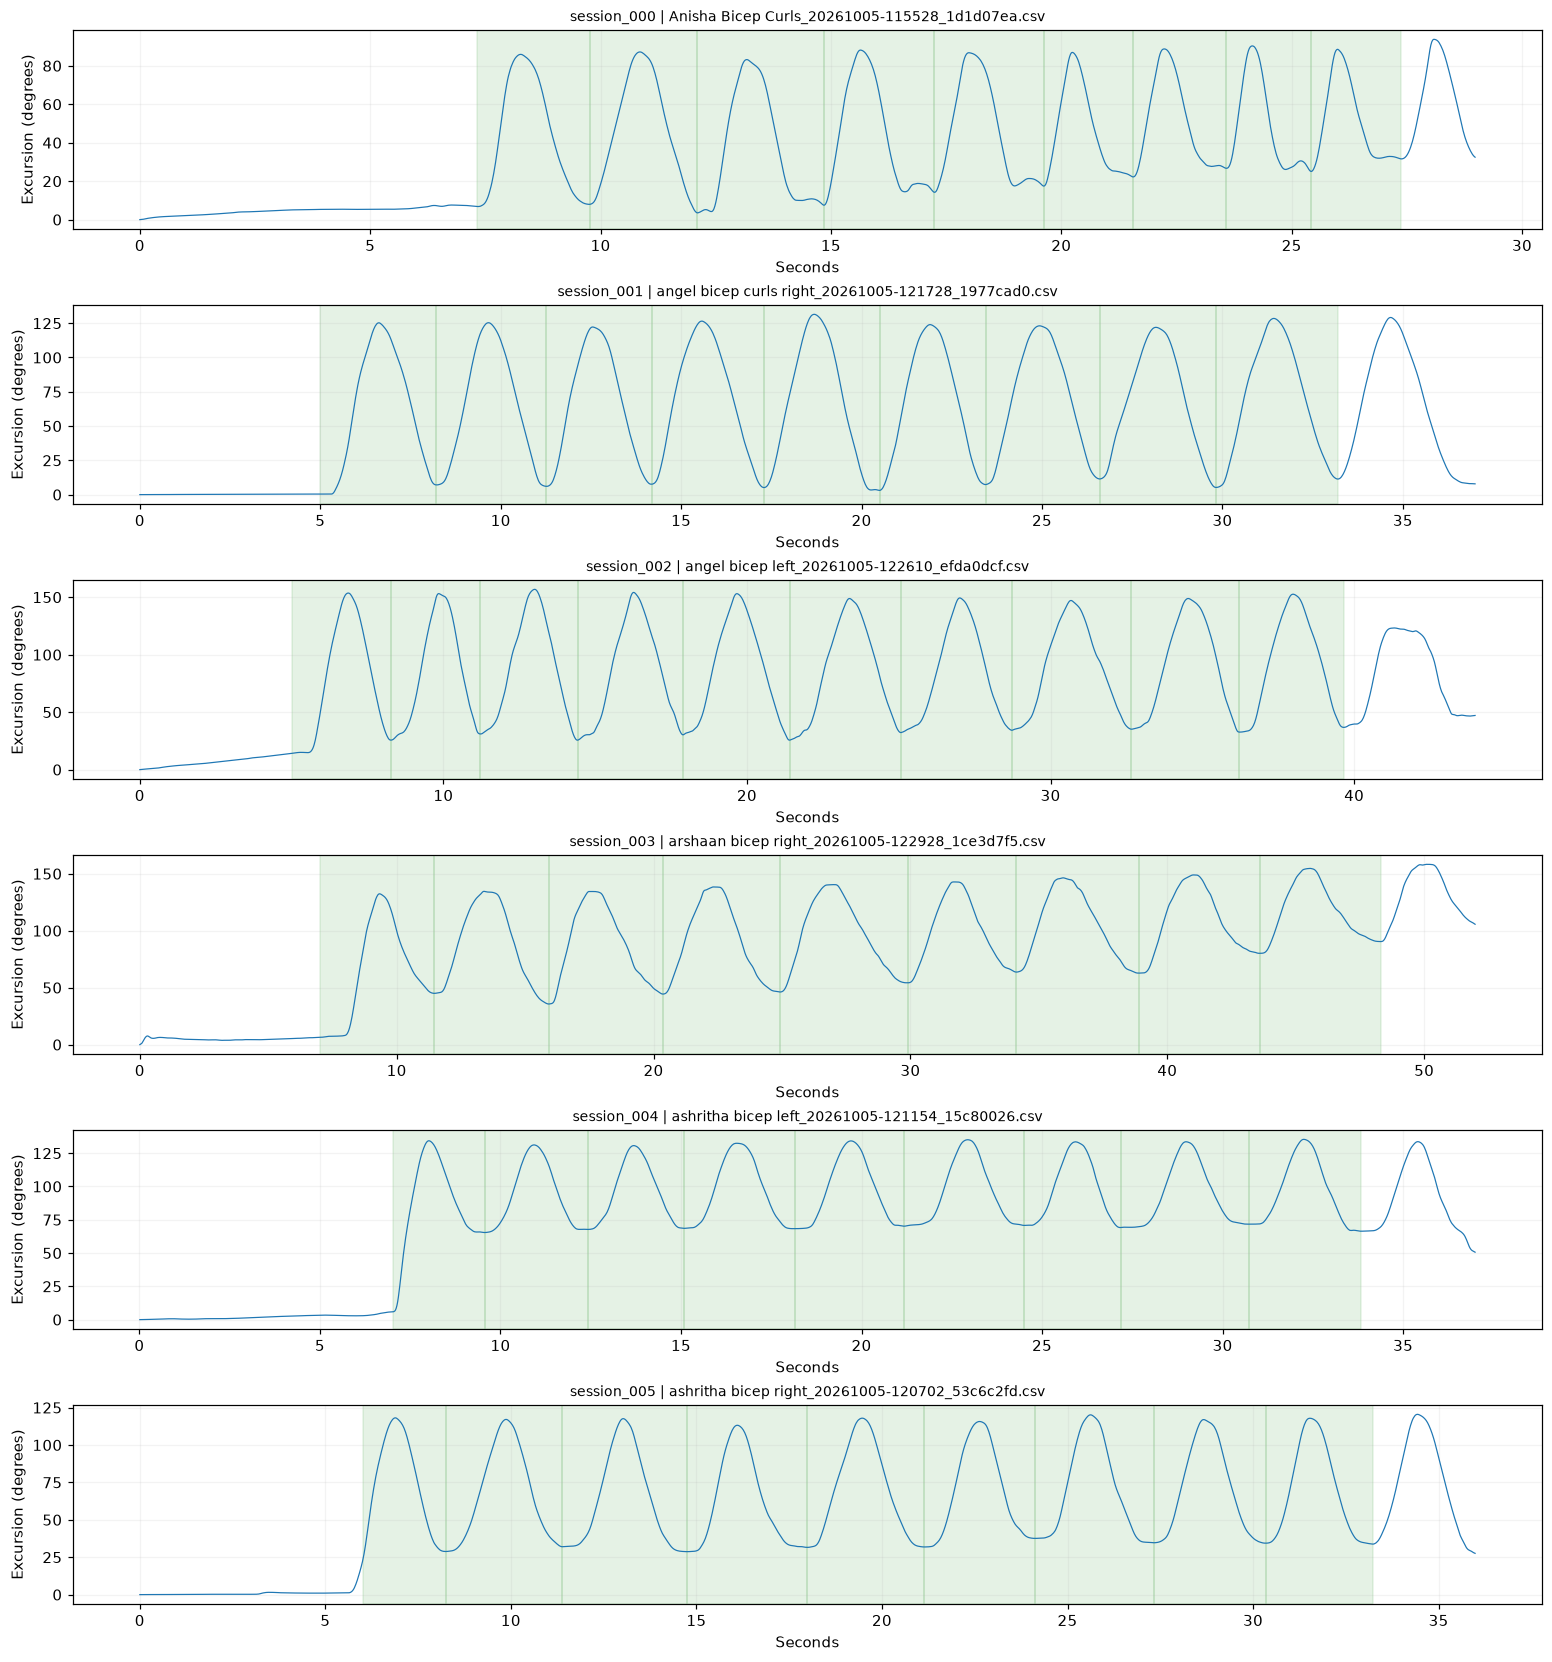

In [5]:
features_rows=[];rejections=[];session_audit=[];traces={}
for r in manifest:
    try:
        if r['source']=='watch' and r['window'] is None:raise ValueError('Missing movement window')
        a,g=load_streams(r)
        window=r['window'] or (max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0]))
        # Exclude later handling from watch reconstruction; retain its initial pose.
        a=a[a[:,0]<=window[1]];g=g[g[:,0]<=window[1]]
        accepted,rejected,trace=process(a,g,window);traces[r['session_id']]=trace
        tags={k:r[k] for k in ['session_id','source','participant','side','label','label_status','split']}
        features_rows.extend(dict(tags,**x) for x in accepted)
        rejections.extend(dict(tags,**x) for x in rejected)
        session_audit.append(dict(tags,accepted=len(accepted),rejected=len(rejected),error=''))
    except (ValueError,KeyError,IndexError) as e:session_audit.append(dict(session_id=r['session_id'],source=r['source'],accepted=0,rejected=0,error=str(e)))
def save_table(name,rows):
    if not rows:return
    fields=list(dict.fromkeys(k for r in rows for k in r))
    with (OUTPUT/name).open('w',newline='') as f:w=csv.DictWriter(f,fieldnames=fields);w.writeheader();w.writerows(rows)
save_table('features.csv',features_rows);save_table('rejected_candidates.csv',rejections);save_table('session_audit.csv',session_audit)
for source in ['watch']:
    for split in ['train','validation','test','external']:
        group=[r for r in features_rows if r['source']==source and r['split']==split]
        if group:print(source,split,'typical',sum(r['label']==0 for r in group),'atypical',sum(r['label']==1 for r in group))
print('Errors:',[r for r in session_audit if r['error']])
selected=manifest
fig,axes=plt.subplots(len(selected),1,figsize=(14,2.5*len(selected)),constrained_layout=True)
for ax,r in zip(axes,selected):
    trace=traces.get(r['session_id'],np.empty((0,8)))
    if len(trace):
        for b in np.unique(trace[:,-1]):
            z=trace[trace[:,-1]==b];ax.plot(z[:,0],z[:,4],lw=.8)
    for f in features_rows:
        if f['session_id']==r['session_id']:ax.axvspan(f['start_sec'],f['end_sec'],color='green',alpha=.1)
    ax.set_title(r['session_id']+' | '+Path(r['file']).name,fontsize=9);ax.set_ylabel('Excursion (degrees)');ax.set_xlabel('Seconds');ax.grid(alpha=.15)
fig.savefig(OUTPUT/'segmentation_review.png',dpi=110);plt.show()

## 4 Train on all extracted repetitions and plot scores
Both the scaler and forest use everyone. Higher scores mean more unusual relative to this training group. The dashed line is an exploratory training-score cutoff. Colors show participants, not train/test subsets. Shared bin edges allow comparison; density normalizes each participant histogram to area one.

Training repetitions: 55 Participants: 4
Provisional cutoff: 0.07092679837332022 Flagged training reps: 3


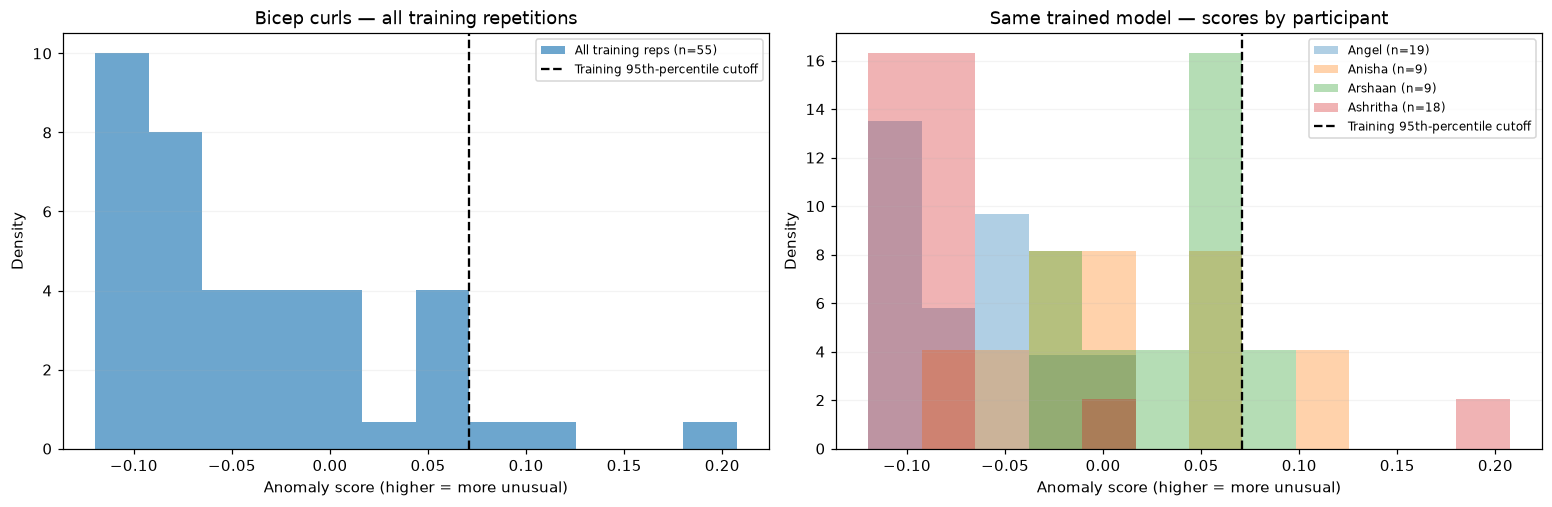

In [6]:
X=np.array([[r[k] for k in FEATURES] for r in features_rows]);assert np.isfinite(X).all()
people=np.array([r['participant'] for r in features_rows])
all_scaler=StandardScaler().fit(X)
all_forest=IsolationForest(n_estimators=300,contamination='auto',random_state=SEED,n_jobs=-1).fit(all_scaler.transform(X))
all_scores=-all_forest.decision_function(all_scaler.transform(X))
all_threshold=float(np.quantile(all_scores,.95))
bins=np.histogram_bin_edges(all_scores,bins=12)
fig,axes=plt.subplots(1,2,figsize=(14,4.5),sharex=True,constrained_layout=True)
axes[0].hist(all_scores,bins=bins,density=True,alpha=.65,label=f'All training reps (n={len(X)})')
for person in sorted(set(people)):
    values=all_scores[people==person]
    axes[1].hist(values,bins=bins,density=True,alpha=.35,label=f'{person.title()} (n={len(values)})')
for ax in axes:
    ax.axvline(all_threshold,color='black',ls='--',label='Training 95th-percentile cutoff')
    ax.set_xlabel('Anomaly score (higher = more unusual)');ax.set_ylabel('Density');ax.legend(fontsize=8);ax.grid(axis='y',alpha=.15)
axes[0].set_title('Bicep curls — all training repetitions')
axes[1].set_title('Same trained model — scores by participant')
fig.savefig(OUTPUT/'training_score_histogram.png',dpi=150)
plt.show()
score_rows=[dict(r,anomaly_score=float(s),flagged=bool(s>all_threshold)) for r,s in zip(features_rows,all_scores)]
save_table('training_scores.csv',score_rows)
print('Training repetitions:',len(X),'Participants:',len(set(people)))
print('Provisional cutoff:',all_threshold,'Flagged training reps:',int((all_scores>all_threshold).sum()))


## 5 Save the all-watch candidate
Save the fitted scaler, forest, threshold and exact preprocessing together. These training histograms describe fit; no independent test performance is claimed.

In [7]:
metadata=dict(feature_order=FEATURES,sampling_rate_hz=FS,seed=SEED,input_contract={'acceleration':'total acceleration including gravity, XYZ g','gyroscope':'XYZ degrees/s','timestamp':'shared-clock seconds'},score_convention='negative decision_function; flag score > threshold',active_model_changed=False,ready_to_replace=False,versions={'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__},limitations=['Assumed typical labels','First wearing windows only','No atypical watch evaluation','All data used for training; no held-out evaluation','Segmentation and live replay require review'])
for name,sc,fo,th,method in [('all_watch_candidate',all_scaler,all_forest,all_threshold,'95th percentile of own training scores; unvalidated')]:
    bundle=OUTPUT/name;bundle.mkdir()
    for key,obj in [('scaler',sc),('forest',fo)]:
        with (bundle/(key+'.pkl')).open('wb') as f:pickle.dump(obj,f)
    (bundle/'metadata.json').write_text(json.dumps(dict(metadata,threshold=th,threshold_method=method,training_repetitions=len(X)),indent=2))
    with (bundle/'forest.pkl').open('rb') as f:restored=pickle.load(f)
    assert np.allclose(-restored.decision_function(sc.transform(X)),-fo.decision_function(sc.transform(X)))
print('All-watch candidate trained on',len(X),'repetitions from',len(set(people)),'participants.')
print('Saved models to',OUTPUT)


All-watch candidate trained on 55 repetitions from 4 participants.
Saved models to /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_watch_only_runs/20261017T170731771444Z


In [8]:
preprocessing_source='"""Experimental eight-feature pipeline. Fixed sensor rotations preserve magnitudes; placement and sensor errors still matter."""\nimport numpy as np\nfrom scipy.spatial.transform import Rotation\nfrom collections import deque\nfrom itertools import combinations\nFS=50.0\nFEATURES=[\'duration_seconds\',\'completion_error_deg\',\'gyro_mean_deg_s\',\'gyro_peak_deg_s\',\'gyro_std_deg_s\',\'angular_path_deg\',\'accel_magnitude_std_g\',\'gyro_high_low_power_ratio\']\n\nclass OrientationStream:\n    def __init__(self):\n        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)\n    def update(self,t,accel,gyro):\n        if self.last is not None and t-self.last>.060001:self.__init__()\n        if self.r is None:\n            if not .5<np.linalg.norm(accel)<1.5:return None\n            x,y,z=accel; self.r=Rotation.from_euler(\'xyz\',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r\n        else:\n            dt=t-self.last; omega=np.deg2rad(gyro)\n            norm=np.linalg.norm(accel)\n            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))\n            self.r=self.r*Rotation.from_rotvec(omega*dt)\n        self.last=t\n        relative=self.r0.inv()*self.r\n        excursion=np.rad2deg(relative.magnitude())\n        return self.r.as_quat(),excursion\n\nclass RepStream:\n    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""\n    def __init__(self):self.mode=\'seek\';self.low=None;self.high=None;self.start=None\n    def update(self,i,value):\n        if self.low is None:self.low=(i,value);return None\n        if self.mode in [\'seek\',\'rise\']:\n            if value<self.low[1]:self.low=(i,value)\n            if self.mode==\'seek\' and value-self.low[1]>=15:\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n            elif self.mode==\'rise\':\n                if self.high is None or value>self.high[1]:self.high=(i,value)\n                if self.high[1]-value>=8:self.low=(i,value);self.mode=\'fall\'\n        else:\n            if value<self.low[1]:self.low=(i,value)\n            if value-self.low[1]>=8:\n                result=(self.start,self.low[0],i)\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n                return result\n        return None\n\ndef features(t,q,accel,gyro):\n    speed=np.linalg.norm(gyro,axis=1)\n    # Endpoint orientation distance, not Euler-angle summation.\n    error=np.rad2deg((Rotation.from_quat(q[0]).inv()*Rotation.from_quat(q[-1])).magnitude())\n    from scipy.signal import periodogram\n    freq,power=periodogram(speed,fs=FS,window=\'hann\',detrend=\'constant\',scaling=\'spectrum\')\n    low=float(power[(freq>=.1)&(freq<=2)].sum())\n    high=float(power[(freq>=3)&(freq<=8)].sum())\n    values=[t[-1]-t[0],error,speed.mean(),speed.max(),speed.std(),np.trapezoid(speed,t),np.linalg.norm(accel,axis=1).std(),high/max(low,1e-8)]\n    return dict(zip(FEATURES,map(float,values)))\n\ndef align_streams(accel,gyro):\n    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.\n    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]\n    if min(len(a),len(g))<5:return np.empty((0,8))\n    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError(\'Nonmonotonic timestamps\')\n    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)\n    ai=np.searchsorted(a[:,0],t,side=\'right\')-1;gi=np.searchsorted(g[:,0],t,side=\'right\')-1\n    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001\n    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])\n\ndef process(accel,gyro,window):\n    joined=align_streams(accel,gyro)\n    # Existing stationary lead-in only. Never estimate bias from moving repetitions.\n    lead=joined[(joined[:,0]<min(window[0],2))] if len(joined) else joined\n    bias=np.zeros(3)\n    if len(lead)>=50 and np.std(np.linalg.norm(lead[:,1:4],axis=1))<.03 and np.max(np.linalg.norm(lead[:,4:7],axis=1))<5:\n        bias=np.mean(lead[:,4:7],axis=0)\n    state=OrientationStream();detector=RepStream();trace=[];raw=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)\n    for row in joined:\n        t=row[0];gyro=row[4:7]-bias\n        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1\n        last=t\n        value=state.update(t,row[1:4],gyro)\n        if value is None:continue\n        quat,excursion=value;history.append(excursion);excursion=float(np.mean(history))\n        index=len(trace)\n        trace.append([t,0,0,0,excursion,row[7],0,block])\n        raw.append([t,*quat,*row[1:4],*gyro])\n        if t<window[0] or t>window[1]:detector=RepStream();continue\n        result=detector.update(index,excursion)\n        if result is None:continue\n        start,end,emit=result;rep=np.array(trace[start:end+1]);data=np.array(raw[start:end+1]);duration=rep[-1,0]-rep[0,0]\n        reasons=[]\n        if not .6<=duration<=8:reasons.append(\'duration outside engineering bounds\')\n        if np.ptp(rep[:,4])<15:reasons.append(\'excursion below 15 degrees\')\n        if np.mean(rep[:,5]>.04)>.1:reasons.append(\'excess stale sensor samples\')\n        record={\'start_sec\':float(rep[0,0]),\'end_sec\':float(rep[-1,0]),\'emitted_at_sec\':float(t),\'feedback_delay_sec\':float(t-rep[-1,0]),\'block\':block,\'held_sample_fraction\':float(np.mean(rep[:,5]>.002))}\n        if reasons:rejected.append(dict(record,reason=\'; \'.join(reasons)))\n        else:accepted.append(dict(record,**features(data[:,0],data[:,1:5],data[:,5:8],data[:,8:11])))\n    return accepted,rejected,np.asarray(trace)'
for name in ['all_watch_candidate']:(OUTPUT/name/'preprocessing.py').write_text(preprocessing_source)


### Interpretation
Everyone contributed to the model. Differences between the colored histograms show how scores vary across participants within the training data. A flagged repetition is unusual relative to these examples, not proof of incorrect form. The cutoff is provisional; these plots do not measure generalization.

## 6 External atypical Mbient histogram — no retraining
Score every explicitly atypical accelerometer/gyroscope pair in `mbientcode/mbientdata`, deduplicated by paired file hashes. Currently one pair is explicitly labeled: `left_atypical`. Timestamp-only files have unverified labels and are not treated as additional atypical recordings.

Apply exactly the watch-trained scaler, forest and cutoff. Synchronize Mbient streams using epoch timestamps; acceleration is g and gyro degrees/s. The same feature extraction and candidate segmentation are used. Review boundaries below: setup, incomplete cycles and fragmentation can affect these candidate-level results.

This comparison confounds device and movement differences: separation from watch training scores alone does not prove detection of incorrect form. No cutoff tuning is performed here.

Explicitly atypical recording pairs: 1
Accepted candidate repetitions: 16 Rejected: 1
Flagged by unchanged watch cutoff: 16 / 16
Watch training cutoff: 0.07092679837332022


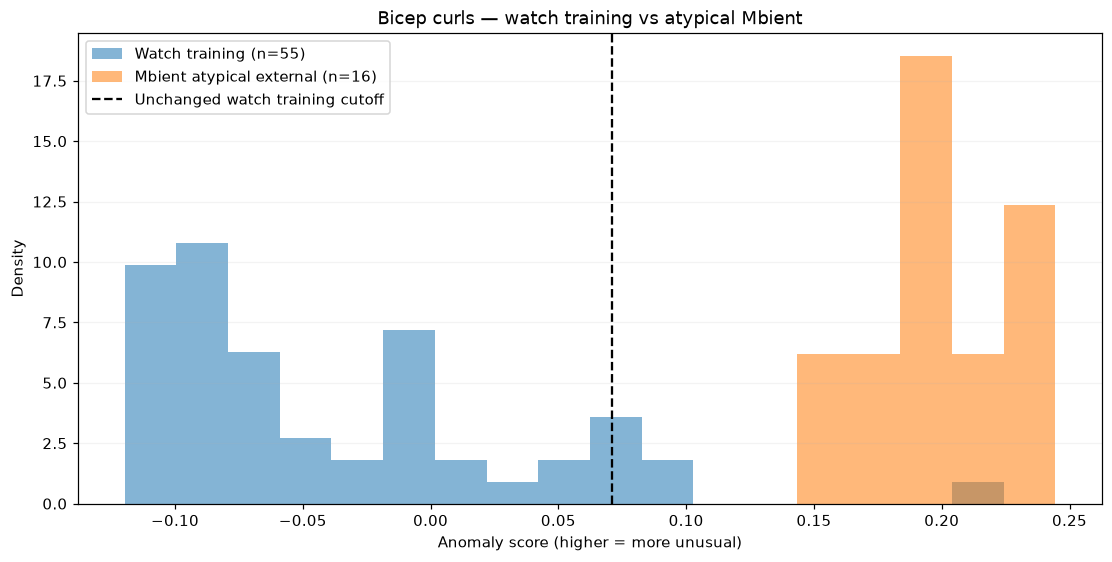

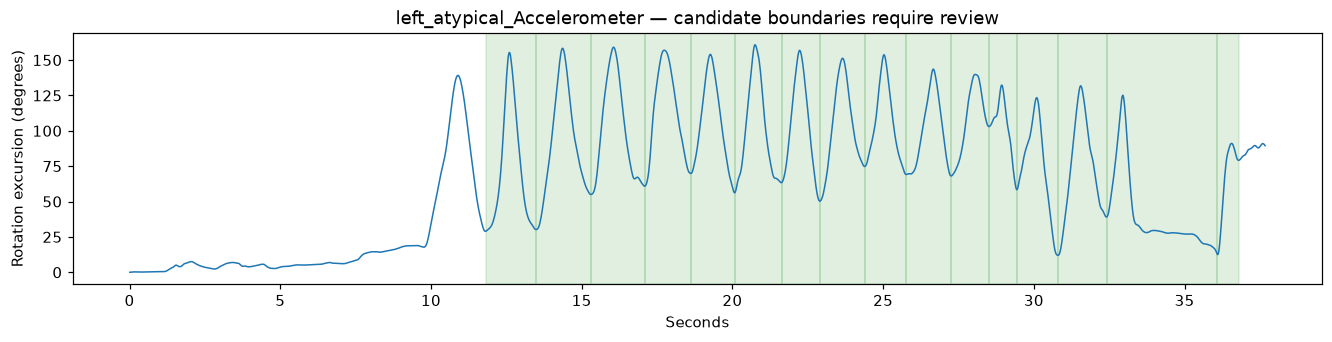

In [9]:
MBIENT_DIR=REPO/'mbientcode/mbientdata'
external_rows=[];external_rejections=[];external_manifest=[];external_traces=[];seen_pairs=set()
def read_mbient_stream(path):
    rows=readcsv(path);keys=list(rows[0])
    assert len(keys)==6, 'Check Mbient CSV column layout'
    return np.array([[float(r[keys[0]])/1000,*[float(r[k]) for k in keys[3:6]]] for r in rows])
for ap in sorted(MBIENT_DIR.glob('*_Accelerometer.csv')):
    if 'atypical' not in ap.name.lower():continue
    gp=ap.with_name(ap.name.replace('_Accelerometer.csv','_Gyroscope.csv'))
    if not gp.exists():raise FileNotFoundError(f'Missing paired gyroscope: {gp}')
    pair_hash=(digest(ap),digest(gp))
    if pair_hash in seen_pairs:continue
    seen_pairs.add(pair_hash)
    a,g=read_mbient_stream(ap),read_mbient_stream(gp)
    origin=min(a[0,0],g[0,0]);a[:,0]-=origin;g[:,0]-=origin
    window=(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0]))
    accepted,rejected,trace=process(a,g,window)
    external_rows.extend(dict(recording=ap.stem,**r) for r in accepted)
    external_rejections.extend(dict(recording=ap.stem,**r) for r in rejected)
    external_manifest.append(dict(accelerometer=str(ap),gyroscope=str(gp),sha256=pair_hash,accepted=len(accepted),rejected=len(rejected),label='atypical from filename'))
    external_traces.append((ap.stem,trace,accepted))
assert external_rows,'No usable explicitly labeled atypical Mbient repetitions found'
Xm=np.array([[r[k] for k in FEATURES] for r in external_rows]);assert np.isfinite(Xm).all()
mbient_scores=-all_forest.decision_function(all_scaler.transform(Xm))
for r,s in zip(external_rows,mbient_scores):r.update(anomaly_score=float(s),flagged=bool(s>all_threshold))
save_table('mbient_atypical_scores.csv',external_rows)
save_table('mbient_atypical_rejections.csv',external_rejections)
(OUTPUT/'mbient_atypical_manifest.json').write_text(json.dumps(external_manifest,indent=2))
print('Explicitly atypical recording pairs:',len(external_manifest))
print('Accepted candidate repetitions:',len(external_rows),'Rejected:',len(external_rejections))
print('Flagged by unchanged watch cutoff:',int((mbient_scores>all_threshold).sum()),'/',len(mbient_scores))
print('Watch training cutoff:',all_threshold)
combined_bins=np.histogram_bin_edges(np.r_[all_scores,mbient_scores],bins=18)
fig,ax=plt.subplots(figsize=(10,5),constrained_layout=True)
ax.hist(all_scores,bins=combined_bins,density=True,alpha=.55,label=f'Watch training (n={len(all_scores)})')
ax.hist(mbient_scores,bins=combined_bins,density=True,alpha=.55,label=f'Mbient atypical external (n={len(mbient_scores)})')
ax.axvline(all_threshold,color='black',ls='--',label='Unchanged watch training cutoff')
ax.set(title='Bicep curls — watch training vs atypical Mbient',xlabel='Anomaly score (higher = more unusual)',ylabel='Density')
ax.legend();ax.grid(axis='y',alpha=.15)
fig.savefig(OUTPUT/'watch_vs_mbient_atypical_histogram.png',dpi=150);plt.show()
fig,axes=plt.subplots(len(external_traces),1,figsize=(12,3*len(external_traces)),squeeze=False,constrained_layout=True)
for ax,(name,trace,reps) in zip(axes.flat,external_traces):
    ax.plot(trace[:,0],trace[:,4],lw=1)
    for r in reps:ax.axvspan(r['start_sec'],r['end_sec'],alpha=.12,color='green')
    ax.set(title=name+' — candidate boundaries require review',xlabel='Seconds',ylabel='Rotation excursion (degrees)')
fig.savefig(OUTPUT/'mbient_atypical_segmentation.png',dpi=130);plt.show()
